# Predictive Marketing Intelligence
## Forecasting Customer Purchase Intent Using Machine Learning

**Project type:** PGDM / Business Analytics educational project  
**Business focus:** E-commerce customer behaviour and purchase-intent prediction

### Research question
Can online shopping-session behaviour help distinguish sessions that end in a purchase from sessions that do not?

### Dataset source
UCI Machine Learning Repository — Online Shoppers Purchasing Intention Dataset. The dataset contains session-level behaviour and a binary target called `Revenue`.

In [11]:
%pip -q install ucimlrepo

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme()

## 1. Data Collection

The next cell retrieves the dataset from UCI using its dataset ID. An internet connection is required.

In [13]:
dataset = fetch_ucirepo(id=468)
X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# The target column is named Revenue. Convert True/False labels to 1/0.
target = y["Revenue"].astype(str).str.lower().map({"true": 1, "false": 0})

print("Feature shape:", X.shape)
print("Target shape:", target.shape)
display(X.head())

Feature shape: (12330, 17)
Target shape: (12330,)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


## 2. Data Understanding and Quality Checks

Check column types, missing values, duplicates, and target balance before modelling.

In [14]:
print("Dataset shape:", X.shape)
print("\nColumn types:")
display(X.dtypes.to_frame("data_type"))

print("\nMissing values per column:")
display(X.isna().sum().to_frame("missing_values"))

print("\nDuplicate feature rows:", X.duplicated().sum())
print("\nTarget distribution:")
display(target.value_counts().rename(index={0: "No purchase", 1: "Purchase"}).to_frame("sessions"))

print("\nPurchase rate: {:.2%}".format(target.mean()))

Dataset shape: (12330, 17)

Column types:


,data_type
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Missing values per column:


,missing_values
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0



Duplicate feature rows: 125

Target distribution:


,sessions
Revenue,
No purchase,10422
Purchase,1908



Purchase rate: 15.47%


## 3. Exploratory Data Analysis (EDA)

Because purchases are the minority class in this dataset, accuracy alone may be misleading. Inspect the class balance and behaviour patterns before drawing conclusions.

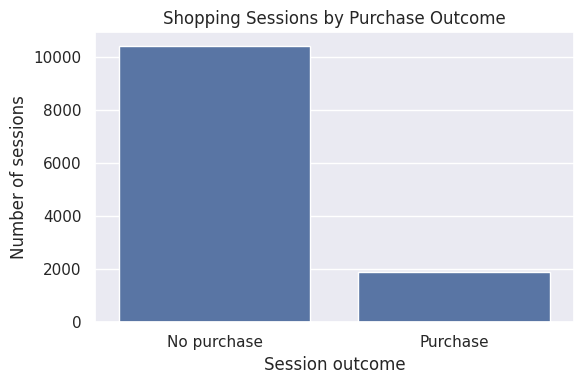

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(x=target.map({0: "No purchase", 1: "Purchase"}))
plt.title("Shopping Sessions by Purchase Outcome")
plt.xlabel("Session outcome")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

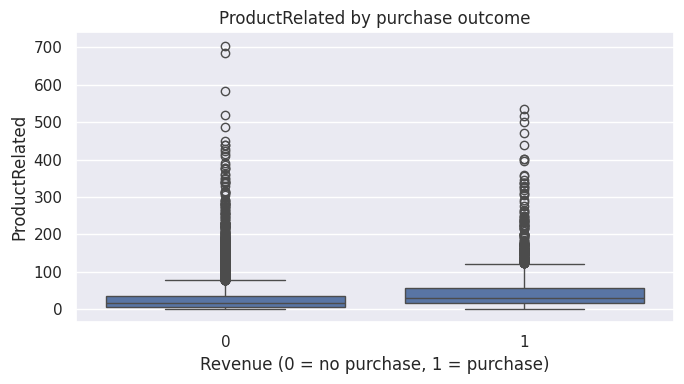

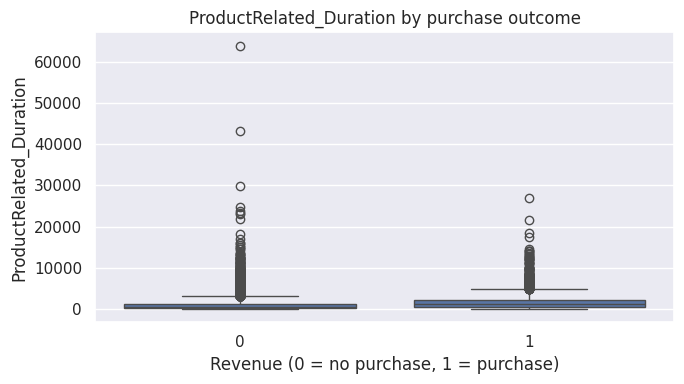

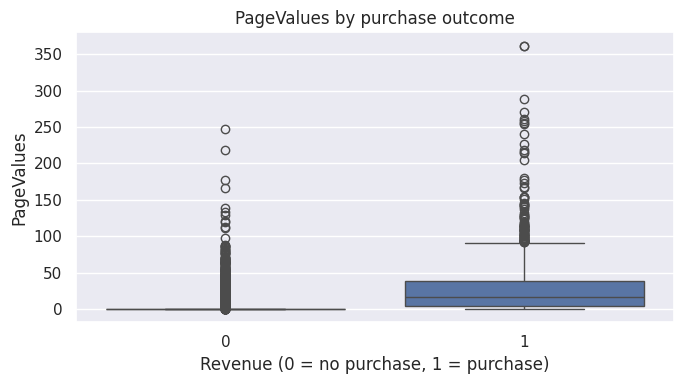

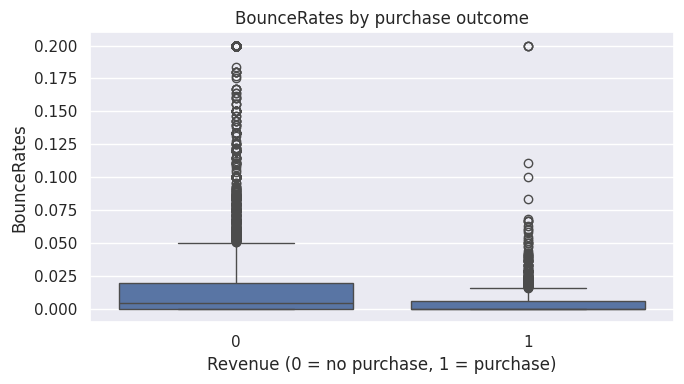

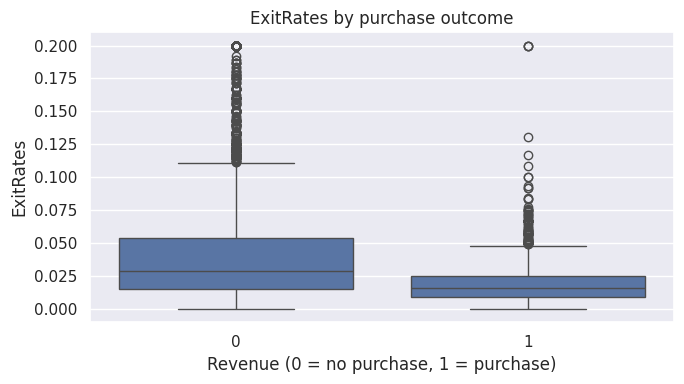

In [16]:
eda_df = X.copy()
eda_df["Revenue"] = target

for col in ["ProductRelated", "ProductRelated_Duration", "PageValues", "BounceRates", "ExitRates"]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=eda_df, x="Revenue", y=col)
    plt.title(f"{col} by purchase outcome")
    plt.xlabel("Revenue (0 = no purchase, 1 = purchase)")
    plt.tight_layout()
    plt.show()

In [17]:
print("Average numerical feature values by purchase outcome:")
display(eda_df.groupby("Revenue").mean(numeric_only=True).T.round(3))

Average numerical feature values by purchase outcome:


Revenue,0,1
Administrative,2.118,3.394
Administrative_Duration,73.740,119.483
Informational,0.452,0.786
Informational_Duration,30.236,57.611
ProductRelated,28.715,48.210
ProductRelated_Duration,1069.988,1876.210
BounceRates,0.025,0.005
ExitRates,0.047,0.020
PageValues,1.976,27.265
SpecialDay,0.068,0.023


### EDA interpretation prompt
After reviewing the charts and table, write 2–3 observations in your own words. For example, check whether product-page activity or page value appears different between purchase and non-purchase sessions. Do not claim a relationship unless the output supports it.

## 4. Prepare Features and Split Data

We use an 80/20 stratified split so that the purchase/non-purchase ratio remains similar in the training and test sets. Categorical features are one-hot encoded; numeric features are median-imputed and scaled. All preprocessing is fitted within each model pipeline.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, target, test_size=0.20, random_state=42, stratify=target
)

categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Training rows: 9864
Testing rows: 2466
Numeric columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']
Categorical columns: ['Month', 'VisitorType']


## 5. Train Classification Models

We compare Logistic Regression (a simple baseline) with Random Forest (a non-linear tree-based model). The results must be calculated by running the notebook; do not insert made-up scores into the report.

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1
    )
}

fitted_models = {}
rows = []

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", classifier)
    ])
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.899,0.750,0.518,0.613,0.924
Logistic Regression,0.850,0.512,0.749,0.608,0.896


## 6. Evaluate the Models

Precision answers: among sessions predicted as purchase, how many actually purchased?  
Recall answers: among all actual purchase sessions, how many did the model identify?  
F1-score balances precision and recall. ROC-AUC measures ranking ability across thresholds.

The best model should not be selected by accuracy alone, especially because the target classes are imbalanced.

Model selected for this prototype by test ROC-AUC: Random Forest

Classification report:
              precision    recall  f1-score   support

 No purchase       0.92      0.97      0.94      2084
    Purchase       0.75      0.52      0.61       382

    accuracy                           0.90      2466
   macro avg       0.83      0.74      0.78      2466
weighted avg       0.89      0.90      0.89      2466



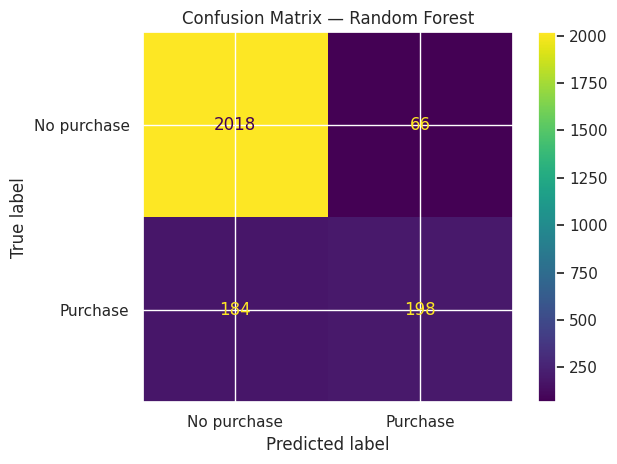

In [20]:
best_model_name = results["ROC-AUC"].idxmax()
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Model selected for this prototype by test ROC-AUC:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, target_names=["No purchase", "Purchase"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["No purchase", "Purchase"],
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 7. Business Insights and Recommendations

Use the actual outputs from your run to complete the table below. Treat these as hypotheses to validate, not guaranteed causes.

| Evidence from your results | Possible marketing action | KPI to monitor |
|---|---|---|
| Product-related engagement differs by outcome | Test product recommendations or helpful product content for relevant sessions | Product-page-to-purchase conversion |
| Page value differs by outcome | Review high-value pages and make their path to checkout clear | Checkout completion rate |
| Model recall is low for purchase sessions | Review the decision threshold and campaign capacity before deployment | Captured purchase sessions and cost per conversion |
| False positives are frequent | Use low-cost, relevant reminders rather than expensive incentives for every flagged session | Incremental conversion and campaign cost |

### Project-specific findings (complete after running)
1. **Most useful observed pattern:** [Purchase sessions had a higher average PageValues (27.265) than non-purchase sessions (1.976).]
2. **Best-performing model and metric:** [Random Forest performed better in ROC-AUC with a score of 0.924, compared with 0.896 for Logistic Regression.]
3. **Business recommendation:** [Marketers should test relevant product recommendations and checkout improvements, then measure their impact on conversion rates.]
4. **Limitation:** This dataset is historical and session-level; it does not prove that a marketing action causes a purchase.

## 8. Conclusion

This project demonstrates an end-to-end business analytics workflow: sourcing data, checking data quality, exploring shopper behaviour, preparing features, training classification models, evaluating results, and translating evidence into marketing recommendations.

Before final submission, replace every bracketed prompt with observations and scores generated by your own notebook run. Explain that model output is an estimate and should be validated on current company data before real-world use.

## Reference
Sakar, C. O. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q